In [1]:
import sys

sys.path.append("..")
from wavelet_transform.utils.new_bubbledynamics import BubbleDynamics as BD
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go

In [2]:
pac = 1e6  # the amplitude of the sine wave in Pa
f0_frequency = 1.1* 1e6  # insonation frequency (Hz)
period = 1 / f0_frequency # the period of the acoustic wave at the fundamental frequency 
fs = f0_frequency * 1e3  # sampling rate to generate the time vector

time_delay = 4 * period  # time delay, t1
pulse_width = 2 * period # pulse width, W = 1 / Q
phase_initial = 0#-0.325 * period  # tau
phase_shift = 0#np.pi / 4  # phi
no_harmonics = 1   # k

R_init = 1e-6  # initial bubble radius in meters
Rdot_init = 0  # initial bubble's wall velocity in m/s

r_measure = 1e-4 # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time

no_cycle = 20  # no. of cycles of the sine wave
deltat = 1.0 / fs
tmax = no_cycle * period
time = np.arange(
    0.0, tmax, deltat
)  # time vector for computing the sine wave, in seconds

In [3]:
BD_obj = BD(
    R_init=R_init,
    Rdot_init = Rdot_init,
    frequency = f0_frequency,
    time = time,
    deltat = deltat,
)

In [4]:
BD_obj.initialize()
BD_obj.add_pac_wave(
    f0_frequency, 
    pac, 
    time_delay, 
    pulse_width, 
    phase_initial, 
    phase_shift, 
    no_harmonics
)

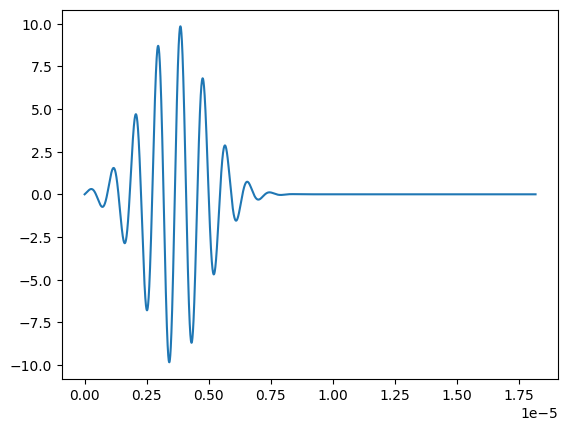

In [5]:
plt.plot(BD_obj.time, BD_obj.npac_wave)
plt.show()

In [6]:
BD_obj.solver()

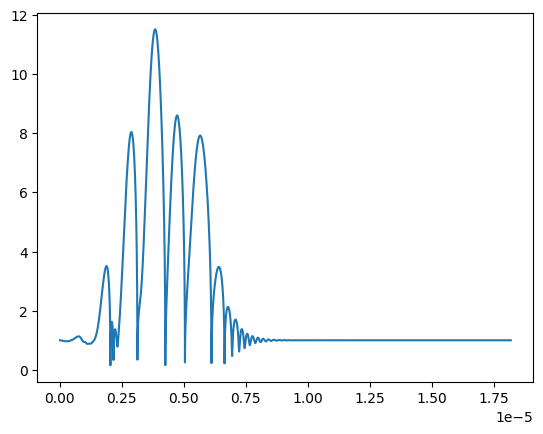

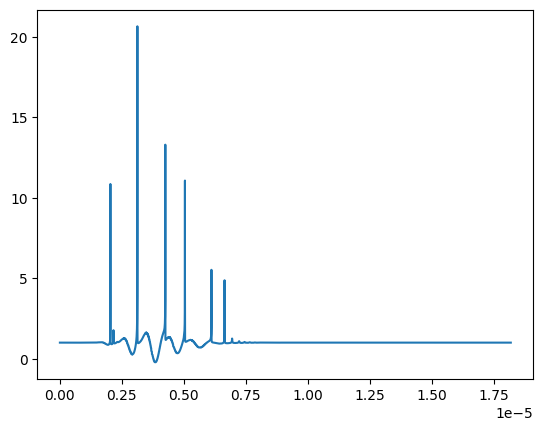

In [7]:
plt.plot(BD_obj.time, BD_obj.R)
plt.show()

BD_obj.calculate_p_radiated(r_measure)
plt.plot(BD_obj.time, BD_obj.p_radiated)
plt.show()
p1 = BD_obj.p_radiated.copy()

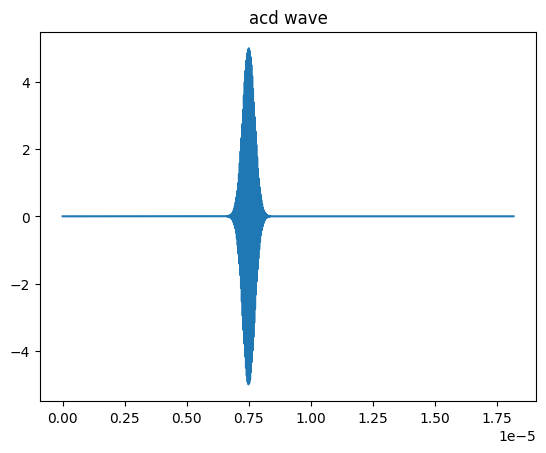

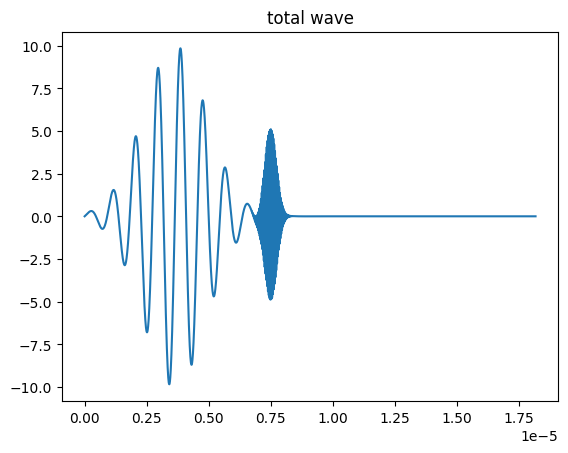

In [8]:
acd_freq = 30e6
acd_pac = 0.5e6
acd_time_delay = 7.5e-6
acd_pulse_width = 10 / acd_freq
BD_obj.add_pac_wave(acd_freq, acd_pac, acd_time_delay, acd_pulse_width, 0, 0, 1)

plt.plot(BD_obj.time, BD_obj.get_npac_wave(-1))
plt.title("acd wave")
plt.show()

plt.plot(BD_obj.time, BD_obj.npac_wave)
plt.title("total wave")
plt.show()

In [9]:
BD_obj.solver()

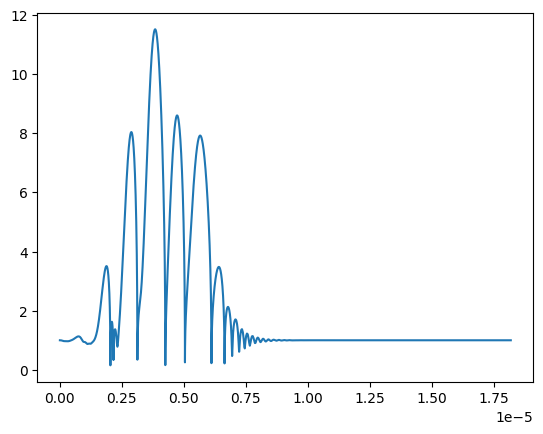

In [10]:
plt.plot(BD_obj.time, BD_obj.R)
plt.show()

In [12]:
BD_obj.calculate_p_radiated(r_measure)
fig = go.Figure()
fig.add_trace(go.Scatter(x=BD_obj.time, y=BD_obj.p_radiated, mode="lines"))
fig.update_layout(
    title="radiated pressure",
    xaxis_title="time/s",
    yaxis_title="pressure/Pa"
)

In [59]:
print(sum(BD_obj.p_radiated - p1))

-0.02686421709768183
